# **Drilling Analysis**
## New wells by month

This notebook contains code to generate a chart showing **new wells vs prices.**

**First,** import relevant libraries and load drilling data

* **New wells by month and operator.**
* **New wells by month based on entry month.**

In [1]:
# Import libraries
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import lines

In [2]:
# Load data
PATH = os.path.join('..', '..', 'data')
df_op = pd.read_csv(PATH+'/oil_intermediate/02_drill_op.csv')
df_entry = pd.read_csv(PATH+'/oil_intermediate/02_well_inventory.csv').rename(columns={'production_start':'fecha'})
df_prices = pd.read_csv(PATH+'/prices_final/02_oil_prices.csv')[['month', 'spot_price_201812_usd', 'f4m_price_201812_usd']].rename(columns={'month':'fecha'})

# Set date format for date columns
df_op['fecha'] = pd.to_datetime(df_op['fecha'], format='%Y-%m-%d')
df_entry['fecha'] = pd.to_datetime(df_entry['fecha'], format='%Y-%m-%d')
df_prices['fecha'] = pd.to_datetime(df_prices['fecha'], format='%Y-%m-%d')

# Aggregate drilling by month in both dataframes and merge with prices
df_agg = (
    pd
    .merge(
        df_entry[(df_entry['fecha'].dt.year>1999) & (df_entry['fecha'].dt.year<2019)].groupby(['fecha'], as_index=False).agg(n_wells_entry = ('nombre_pozo', 'count')),
        df_op.groupby(['fecha'], as_index=False).agg(n_wells_op = ('pozos_perforados', 'sum')),
        how='left',
        on='fecha'
    )
    .merge(
        df_prices,
        how='inner',
        on='fecha',
        validate='1:1'
    )
)

In [8]:
df_agg

,fecha,n_wells_entry,n_wells_op,spot_price_201812_usd,f4m_price_201812_usd
0,2000-01-01,5,NaN,39.500014,35.747078
1,2000-02-01,2,NaN,42.391464,38.162421
2,2000-03-01,7,NaN,42.831228,38.482079
3,2000-04-01,7,NaN,36.835902,34.916769
4,2000-05-01,10,NaN,41.232723,39.156049
...,...,...,...,...,...
223,2018-08-01,13,18.0,68.342515,66.786081
224,2018-09-01,11,5.0,70.407729,69.605705
225,2018-10-01,10,13.0,70.755462,70.715459
226,2018-11-01,9,12.0,56.955164,57.105151


**Second,** create a line chart showing drilling and price series

In [4]:
# Year labels for x-axis labels
x_labels = []

for i in range(2000, 2020, 2):

    l = f'{i}'
    x_labels.append(l)

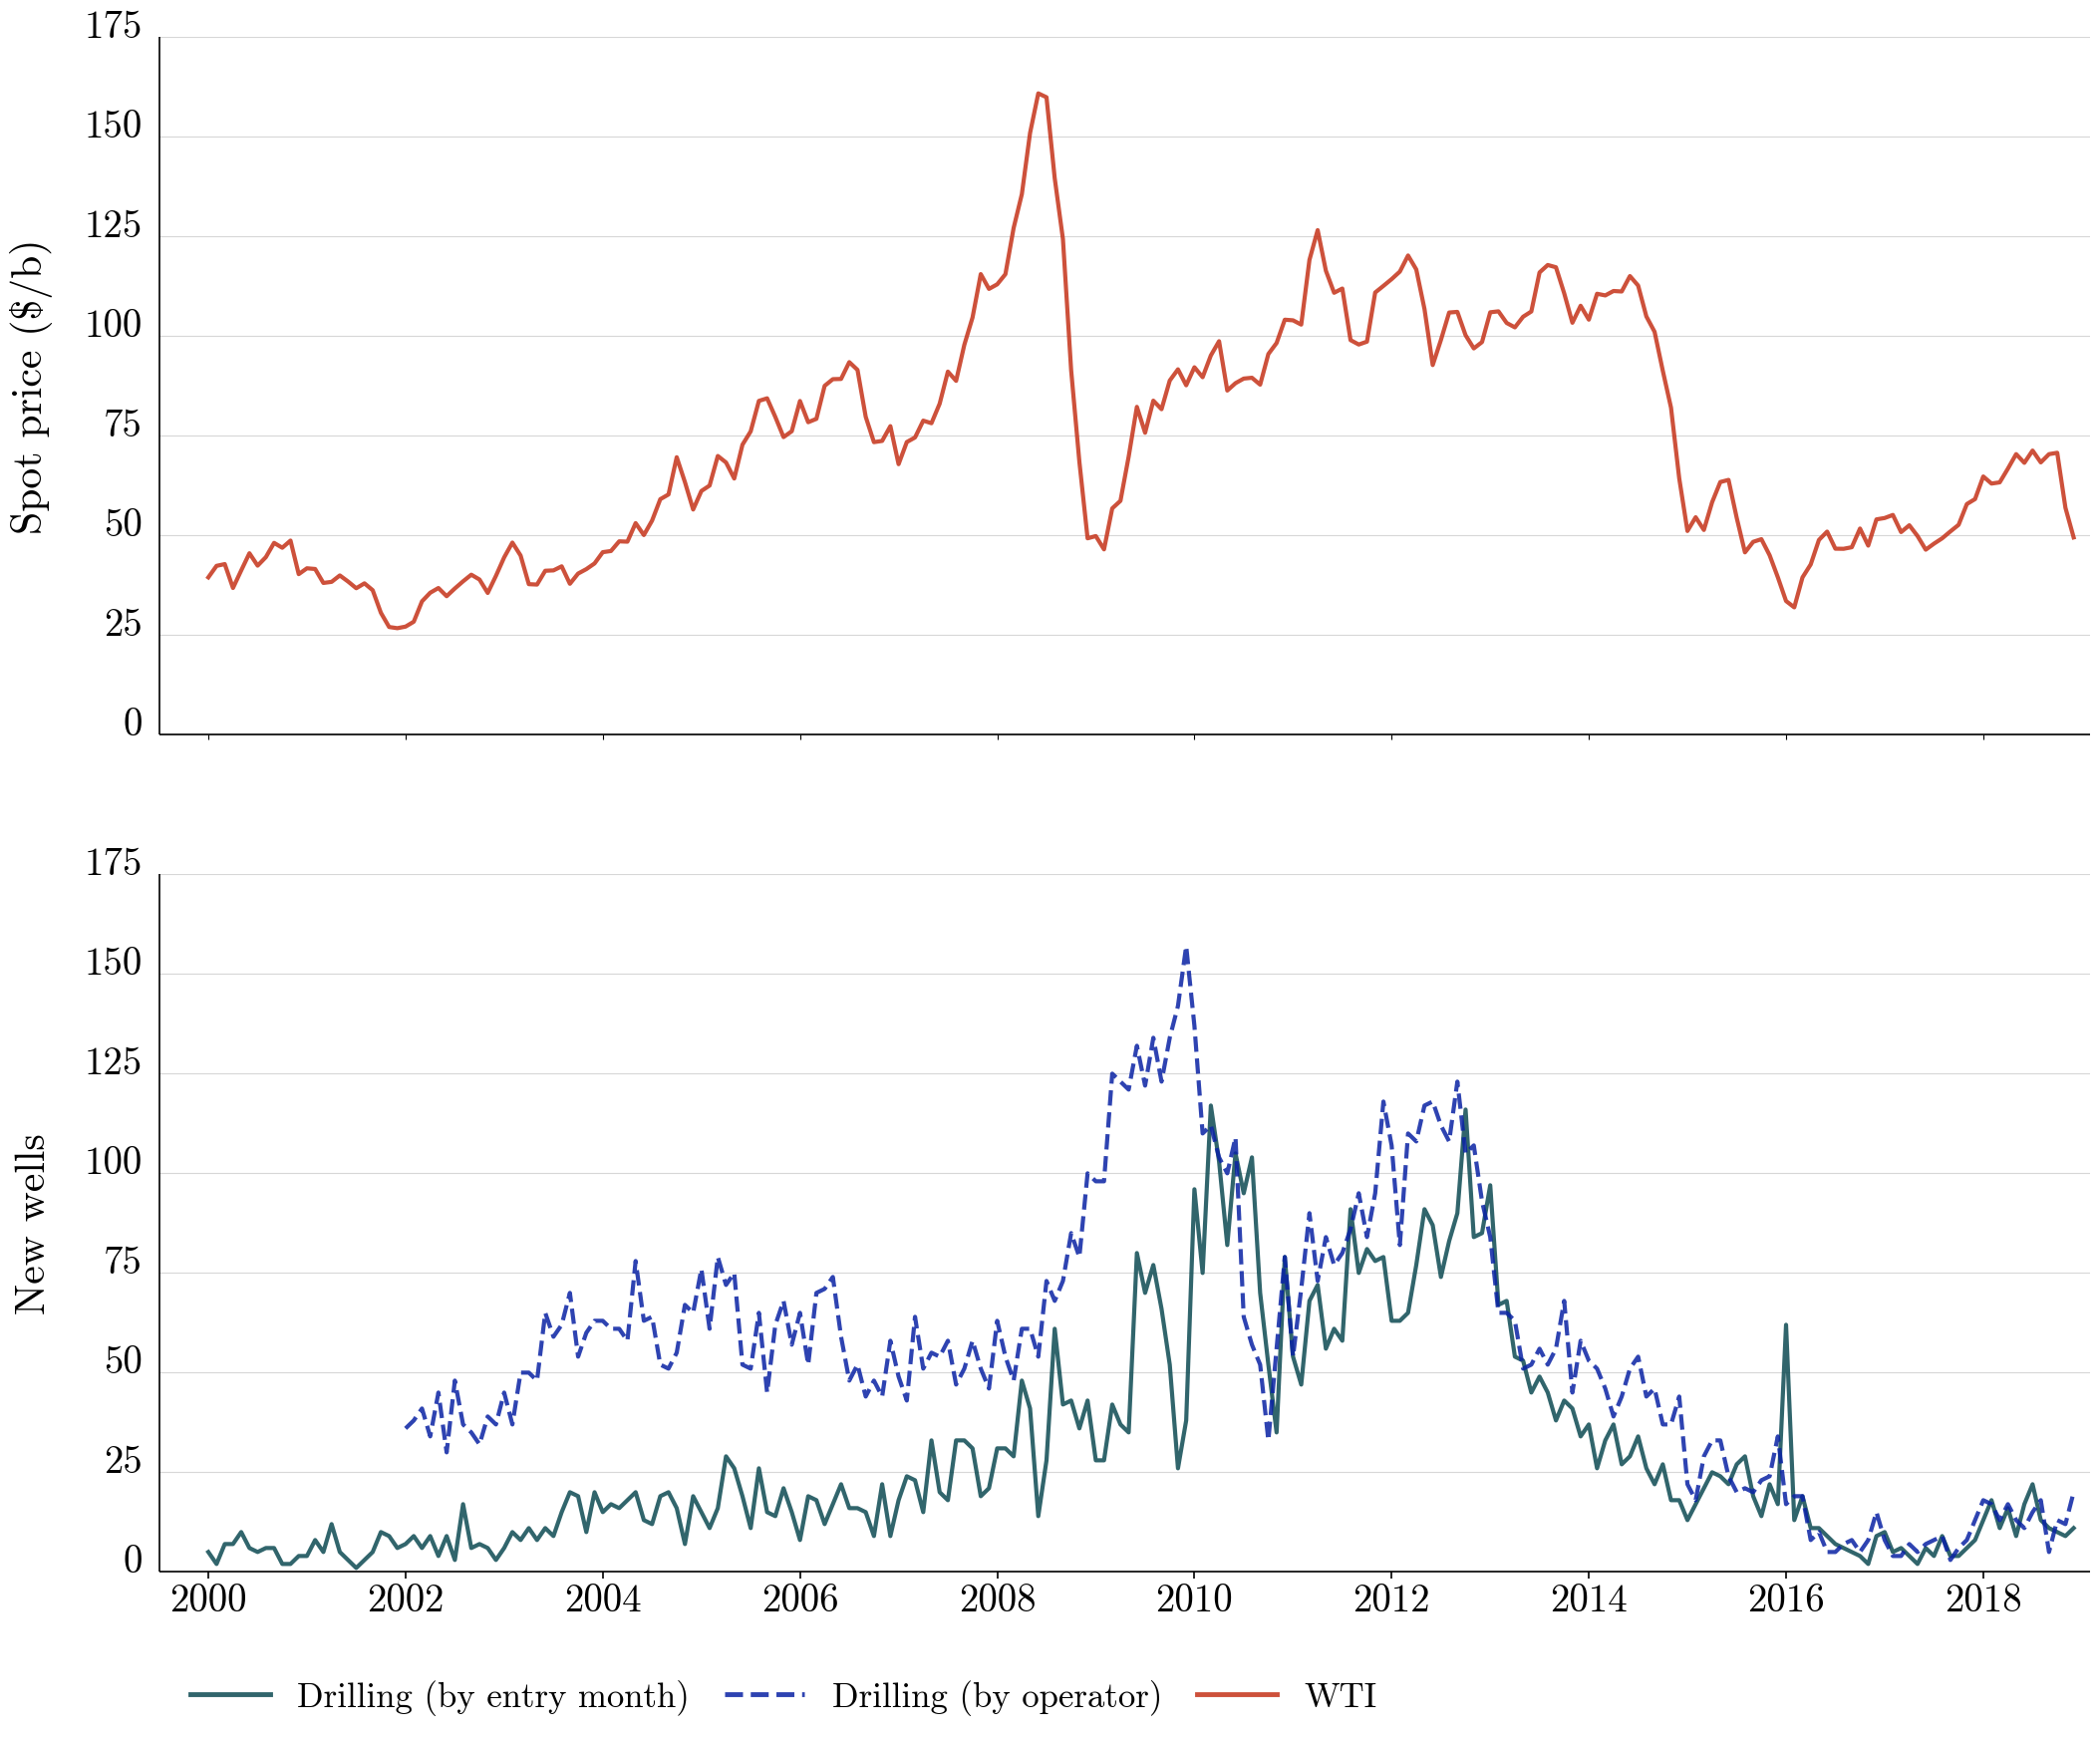

In [13]:
# Create subplots object
fig, axs = plt.subplots(figsize=(25,20), nrows=2, ncols=1, sharex=True)

# PRICES --------------------------------------------------

# Y-axis settings
axs[0].set_ylim(0, 160)
axs[0].set_ylabel('Spot price ($/b)', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label
axs[0].yaxis.set_label_coords(-0.055, 0.5)
axs[0].yaxis.set_tick_params(labelleft=False, length=0)
axs[0].yaxis.set_ticks(list(range(0, 176, 25)))

# Y-axis labels
for i in range(0,176,25):

    axs[0].text(
        0-8, i, f'{i:,}', 
        ha="right", va="baseline", fontsize=28,
        fontfamily="cmr10", fontweight=100
    )

# Spine settings
axs[0].spines["bottom"].set_lw(1.2)
axs[0].spines["bottom"].set_capstyle("butt")
axs[0].spines['left'].set_lw(1.2)
axs[0].spines['left'].set_capstyle("butt")
axs[0].spines["top"].set_visible(False)
axs[0].spines["right"].set_visible(False)

# Grid settings
axs[0].grid(axis='y', alpha=0.5)

# Prices series
axs[0].plot(df_agg['spot_price_201812_usd'].values, lw=3, color="#C53219", alpha=0.85)


# PRODUCTION ----------------------------------------------

# Y-axis settings
axs[1].set_ylim(0, 160)
axs[1].set_ylabel('New wells', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label
axs[1].yaxis.set_label_coords(-0.055, 0.5)
axs[1].yaxis.set_tick_params(labelleft=False, length=0)
axs[1].yaxis.set_ticks(list(range(0, 176, 25)))

# Y-axis labels
for i in range(0,176,25):

    axs[1].text(
        0-8, i, f'{i:,}', 
        ha="right", va="baseline", fontsize=28,
        fontfamily="cmr10", fontweight=100
    )

# X-axis settings
axs[1].set_xlim(-6, 229)
axs[1].xaxis.set_ticks(list(range(0, 229, 24)))
axs[1].xaxis.set_ticklabels(x_labels, fontsize=28, fontweight=100, fontfamily="cmr10")
axs[1].xaxis.set_tick_params(length=5, width=1.2)

# Spine settings
axs[1].spines["bottom"].set_lw(1.2)
axs[1].spines["bottom"].set_capstyle("butt")
axs[1].spines['left'].set_lw(1.2)
axs[1].spines['left'].set_capstyle("butt")
axs[1].spines["top"].set_visible(False)
axs[1].spines["right"].set_visible(False)

# Grid settings
axs[1].grid(axis='y', alpha=0.5)

# Production series
axs[1].plot(df_agg['n_wells_entry'].values, lw=3, color="#0D4A52", alpha=0.85)
axs[1].plot(df_agg['n_wells_op'].values, lw=3, linestyle='--', color="#0922A4", alpha=0.85)

# Legend settings
legend_handles_pr = [
    lines.Line2D([0], [0], color="#0D4A52", lw=3.5, alpha=0.85, label="Drilling (by entry month)"),
    lines.Line2D([0], [0], color="#0922A4", lw=3.5, linestyle='--', alpha=0.85, label="Drilling (by operator)"),
    lines.Line2D([0], [0], color="#C53219", lw=3.5, alpha=0.85, label="WTI")
]

axs[1].legend(
    handles=legend_handles_pr,
    loc="lower left",
    bbox_to_anchor=(0, -0.25),
    bbox_transform=axs[1].transAxes,
    frameon=False,
    ncol=3,
    handlelength=2.3,
    columnspacing=1.0,
    prop={"family": "cmr10", "size": 25}
)

# Show
plt.show()
